# Intertie Schedule Modeling — SP-Tie vs GAP-Tie on the WSCC 9-Bus Network

> **Work in progress** — an illustrative teaching notebook under active development, not an authoritative reference.

An intertie schedule is an import or export agreed at a **scheduling point** on the seam
between two markets. The market determines where on its network that scheduled energy
enters, because that placement sets the power flows, the binding constraints, and the
prices. There are two different designs for placing an intertie schedule:

1) **SP-Tie** (Scheduling-Point Tie), under which the schedule is modeled as an
   injection (import) or a withdrawal (export) at the intertie location, as a fictional
   generator sitting at the scheduling point.
2) **GAP-Tie** (Generation-Aggregation-Point Tie), under which the schedule is modeled
   as sourced from the aggregate generation of the adjacent market, its Default
   Generation Aggregation Point (DGAP), a fixed blend of that market's supply buses.

The two designs place the same megawatts on two different network footprints. This
notebook builds both designs on the WSCC 9-bus network and prices the difference.
SP-Tie can attribute the import's flow to the wrong lines and report congestion that is
not physically there. GAP-Tie tracks the source-to-sink path.

The placement is the only input that varies. The schedule size, the bid, and the
clearing engine are held fixed throughout, so every difference the notebook reports is
attributable to where the megawatts were modeled. The scope of this notebook does not
include losses or unit commitment.

The formulation is built on 101 (nodal fundamentals). Everything runs on the shared
libraries: `wscc9_model`, `footprints`, `seams_engine`, `wscc9_figures`.


## 0. Setup

In [1]:
#@title ▶ Run me first — Colab setup (installs packages, fetches the helper modules)
# On Google Colab this installs the few non-default packages and downloads the
# three helper modules next to the notebook. Running locally it does nothing
# (the modules are already on disk), so the same notebook works in both places.
import sys, subprocess

def _sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main"
    for _f in ("ieee9_network.py", "seams_engine.py", "nodal_plot.py",
              "wscc9_model.py", "footprints.py", "revenue_allocation.py", "wscc9_figures.py",
              "intertie.py"):
        _sh(f"wget -q {_base}/{_f} -O {_f}")
    print("Colab setup complete.")
else:
    print("Local run: using the modules already in this folder.")


Local run: using the modules already in this folder.


In [2]:
import sys, os, importlib
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('pypsa').setLevel(logging.ERROR)
logging.getLogger('ieee9_network').setLevel(logging.WARNING)   # the §6 loop rebuilds the network per draw

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))

# Teaching libraries for the WSCC 9-bus illustrative repository.
import seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures, intertie
for _m in (seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures, intertie):
    importlib.reload(_m)
import wscc9_model as wm, footprints as fpmod, revenue_allocation as ra, wscc9_figures as figs
from wscc9_model import (
    build_network, make_engine, shift_factors, sf_table,
    BUS_COLORS, COORDS, RING_ORDER, ROTATION_DEG, CENTER_BUS,
)
from seams_engine import (
    compute_ptdf, MarketEngine, solve_engine_dispatch,
    physical_flows, seam_dual_gap, to_supply_demand, susceptance_widths,
    shed_segments, served_by_bus, served_demand,
)
from nodal_plot import (
    plot_network_topology, plot_nodal_circlize, plot_combined_letter,
    assign_bus_colors, BUS_PALETTE, TRANSIT_COLOR,
)
pd.set_option('display.width', 160)

figs.install_latex_repr()      # booktabs LaTeX for DataFrames on PDF export

print('ready')

ready

## 1. One intertie, two ways to model it

**Nomenclature.** The `Code` column is where each object lives in the
notebook and the shared libraries.

| Symbol | Code | Definition |
|---|---|---|
| $E$ | `IMPORT_MW` / `EXPORT_MW` | the intertie schedule — the same MW cleared under either placement |
| $p^{\text{imp}}_n$ | the schedule's `exo=` injection | where the schedule's MW sit on the network: at the tie bus (SP-Tie) or spread over the DGAP buses (GAP-Tie) |
| $\mathrm{GDF}_n$ | `DGAP` | the exporter's Default Generation Aggregation Point weight at bus $n$, $\sum_n\mathrm{GDF}_n=1$ |
| $SF_{n,m}$, $SF_{\text{tie},m}$ | `compute_ptdf` | shift factor of bus $n$ (or of the tie bus) on line $m$ |
| $\mathrm{PFC}^{\text{imp}}_m$ | `pfc()` | the schedule's power-flow contribution to line $m$ under each placement |


Two markets share the 9-bus network. **Market A** holds the cheap supply: the
low-cost fleet at buses 2 (\$35) and 3 (\$20), whose capacity-weighted blend is its
**Default Generation Aggregation Point (DGAP)**. **Market B** is the market being cleared: buses
$\{1,4,5,9\}$, one expensive unit at bus 1 (\$50/MWh) and load at buses 5 and 9.

The economic transfer runs from low cost to high: Market A exports to Market B. Market B
buys an **import**: a supply offer for up to $E$ MW, bid at \$37/MWh, slightly above
Market A's \$35 marginal cost, so it clears against Market B's \$50 unit and the
low-cost fleet earns a thin margin. SP-Tie and GAP-Tie agree on the economics (the \$37
bid) and the quantity. They differ only in where the schedule's megawatts sit on the
network for power flow:

$$
\text{SP-Tie:}\quad p^{\text{imp}}_n = +E\ \text{at the tie bus},\qquad\qquad
\text{GAP-Tie:}\quad p^{\text{imp}}_n = +E\,\mathrm{GDF}_n\ \text{at Market A's DGAP buses}. \quad (1)
$$

*In words.* The schedule's injection $p^{\text{imp}}_n$ takes one of two forms. 1) Under SP-Tie, $p^{\text{imp}}_n$ places the full schedule $E$ at the tie bus. 2) Under GAP-Tie, $p^{\text{imp}}_n$ spreads the same schedule $E$ over the exporter's DGAP buses, bus $n$ taking the share $E\,\mathrm{GDF}_n$ set by its blend weight $\mathrm{GDF}_n$.

The schedule's contribution to any line $m$ in the network line set, and therefore its
locational price, follows the shift factor of the location where the schedule was
placed:

$$
\text{PFC}^{\text{imp}}_m = SF_{\text{tie},m}\,E \quad(\text{SP-Tie}),
\qquad
\text{PFC}^{\text{imp}}_m = \Big(\textstyle\sum_n \mathrm{GDF}_n\,SF_{n,m}\Big)E \quad(\text{GAP-Tie}).
\quad (2)
$$

*In words.* The schedule's flow contribution to line $m$, $\mathrm{PFC}^{\text{imp}}_m$, is the schedule $E$ times the shift factor of the location where the schedule was placed. 1) Under SP-Tie that shift factor is the tie bus's shift factor $SF_{\text{tie},m}$. 2) Under GAP-Tie it is the $\mathrm{GDF}_n$-weighted average of the DGAP buses' shift factors $SF_{n,m}$.


In [3]:
GEN_FLEET = dict(wm.DEFAULT_GEN_FLEET)      # {gen: {bus, cost $/MWh, p_nom MW}}
LOADS     = dict(wm.DEFAULT_LOADS)          # {bus: MW}  -- loads at 5 (90), 7 (100), 9 (125)

## -- EDIT -- the two markets, the intertie, and the import.
B_BUSES = ['1', '9', '4', '5']          # the market: unit at bus 1 ($50), load at 5 (90), 9 (125)
A_BUSES = ['2', '8', '7', '6', '3']     # the adjacent market; cheap supply at buses 2 ($35), 3 ($20)
TIE_BUS  = '5'                              # the scheduling point (intertie) into Market B
DGAP     = {'2': 0.64, '3': 0.36}          # capacity-weighted GDFs over Market A's units (300/170 MW)
FLOWGATE, FLOWGATE_MW = 'line_1', 75.0      # Market B-internal constraint (4-5): the "Path 26" analog
IMPORT_MW, IMPORT_BID  = 200.0, 37.0        # 200 MW offered at $37/MWh -- slightly above Market A's $35 marginal (still beats Market B's $50)
SHED_PRICE = 300.0      # an intertie VOLL, deliberately above the 150 the rest of the
                        # series uses: shedding an intertie schedule is a firmness
                        # failure, not an energy shortfall. Lowering it toward 150
                        # narrows the SP-Tie phantom cost reported below.
B_LINES = ['line_0', 'line_1', 'line_2', 'line_8']   # the lines Market B monitors
A_LINES = ['line_3', 'line_4', 'line_5', 'line_6', 'line_7']   # the lines Market A monitors
B_GAP = {'1': 1.0}                       # Market B's generation aggregation point (its single unit, bus 1)
ALL_LOADS = {b: float(v) for b, v in LOADS.items()}    # every load on the transmission element (5, 7, 9)
# ---------------------------------------------------------------------------
build_net = lambda: build_network({FLOWGATE: FLOWGATE_MW})
ptF = compute_ptdf(build_net(), slack_bus='1')
MARKETS = {'Market B': B_BUSES, 'Market A': A_BUSES}
MKT_COLORS = {'Market B': '#2471A3', 'Market A': '#993AFF'}
fp = fpmod.make(ptF, MARKETS, MKT_COLORS, monitored={'Market B': B_LINES,
               'Market A': ['line_3', 'line_4', 'line_5', 'line_6', 'line_7']}, tie_label='seam')
mkt_of = fp.fp_of
COST = ra.cost_by_bus(GEN_FLEET)
IMPORT_COLOR = '#E67E22'                    # the intertie import bid (orange)

# The SP-Tie/GAP-Tie machinery -- the placement, the two clears and the 3-set --
# lives in intertie.py, shared with 322. The context crosses once; the names below
# keep the call sites in this notebook.
intertie.configure(
    importer='Market B', exporter='Market A',
    b_buses=B_BUSES, a_buses=A_BUSES, b_lines=B_LINES, a_lines=A_LINES,
    tie_bus=TIE_BUS, dgap=DGAP, b_gap=B_GAP,
    flowgate=FLOWGATE, flowgate_mw=FLOWGATE_MW,
    schedule_mw=IMPORT_MW, import_bid=IMPORT_BID, shed_price=SHED_PRICE,
    all_loads=ALL_LOADS, fp=fp, mkt_colors=MKT_COLORS, cost=COST,
    import_color=IMPORT_COLOR,
)
tie_inject      = intertie.tie_inject      # the schedule placed per the tie model
tie_clear       = intertie.tie_clear       # Market B's clear with the schedule in it
import_mw       = intertie.import_mw       # the schedule's cleared MW
tie_figure      = intertie.tie_figure
neigh_clear     = intertie.neigh_clear
neigh_figure    = intertie.neigh_figure
combined_actual = intertie.combined_actual
combined_figure = intertie.combined_figure
three_set       = intertie.three_set

# Shift factors of the tie bus and the DGAP to the flowgate -- the heart of the difference.
_li = ptF.line_idx[FLOWGATE]
SF_TIE  = float(ptF.ptdf[_li, ptF.bus_idx[TIE_BUS]])
SF_DGAP = sum(w * float(ptF.ptdf[_li, ptF.bus_idx[b]]) for b, w in DGAP.items())
print(f"Flowgate {FLOWGATE} ({FLOWGATE_MW:.0f} MW).  Shift factor of the import to it:")
print(f"   SP-Tie  (at tie bus {TIE_BUS}):       SF = {SF_TIE:+.3f}")
print(f"   GAP-Tie (DGAP, 0.64*b2 + 0.36*b3):   SF = {SF_DGAP:+.3f}")
print(f"   -> the same {IMPORT_MW:.0f} MW import loads {FLOWGATE} by {SF_TIE*IMPORT_MW:+.0f} MW (SP) "
      f"vs {SF_DGAP*IMPORT_MW:+.0f} MW (GAP).")


Flowgate line_1 (75 MW).  Shift factor of the import to it:

   SP-Tie  (at tie bus 5):       SF = -0.865

   GAP-Tie (DGAP, 0.64*b2 + 0.36*b3):   SF = -0.453

   -> the same 200 MW import loads line_1 by -173 MW (SP) vs -91 MW (GAP).

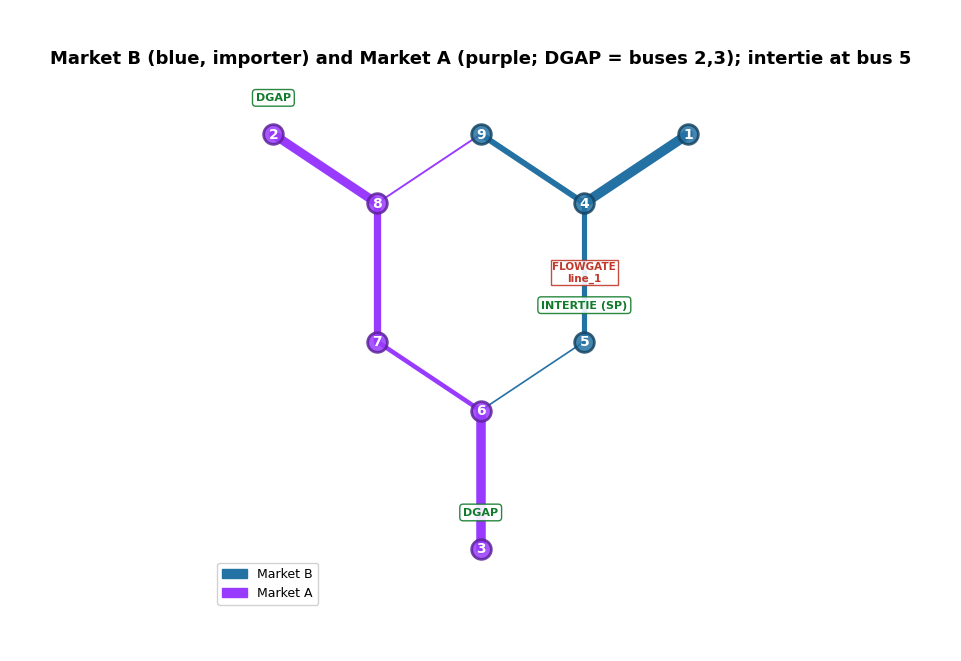

In [4]:
# The two markets on the shared grid: Market B (blue, importer) and Market A
# (purple), whose buses 2 and 3 form the DGAP. The intertie enters Market B at bus 5; the
# flowgate (line_1, 4-5) is the Market B-internal constraint.
import matplotlib.patches as mpatches
_bcol = {b: MKT_COLORS[mkt_of(b)] for b in ptF.buses}
fig, ax = plot_network_topology(
    build_net(), supply_by_bus={}, demand_by_bus={}, bus_colors=_bcol, bus_coords=COORDS,
    line_flows={l: 0.0 for l in ptF.lines}, line_widths=susceptance_widths(ptF),
    line_colors=fp.line_colors(ptF),
    title="Market B (blue, importer) and Market A (purple; DGAP = buses 2,3); intertie at bus 5")
for _b, _t in [(TIE_BUS, "INTERTIE (SP)"), ("2", "DGAP"), ("3", "DGAP")]:
    _x, _y = COORDS[_b]
    ax.annotate(_t, (_x, _y), fontsize=8, fontweight="bold", color="#117A2B", xytext=(0, 24),
                textcoords="offset points", ha="center",
                bbox=dict(boxstyle="round", fc="white", ec="#117A2B", alpha=0.9))
_b0, _b1 = ptF.line_buses[ptF.line_idx[FLOWGATE]]
_x0, _y0 = COORDS[_b0]; _x1, _y1 = COORDS[_b1]
ax.text((_x0+_x1)/2, (_y0+_y1)/2, f"FLOWGATE\n{FLOWGATE}", fontsize=7.5, fontweight="bold",
        color="#C0392B", ha="center", va="center",
        bbox=dict(fc="white", ec="#C0392B", alpha=0.9, pad=1.2))
ax.legend(handles=[mpatches.Patch(color=MKT_COLORS[m], label=m) for m in MARKETS],
          loc="lower left", fontsize=9, framealpha=0.9)
plt.show()


In [5]:
# The import-side 3-set -- tie_figure, neigh_clear, neigh_figure, combined_actual,
# combined_figure and three_set -- is in intertie.py, aliased in the EDIT cell above.
# The export direction below mirrors it: the schedule draws as orange DEMAND at the
# counterparty location instead of as a supply offer.

def b_import_clear(mode, E):
    """For Market A's export, Market B is the IMPORTER (the other footprint): it receives the
    schedule as fixed SUPPLY -- at the shared scheduling point under SP-Tie, at Market A's GAP
    (buses 2,3) under GAP-Tie -- and backs down its own bus-1 unit."""
    net = build_network({A_FLOWGATE: A_FLOWGATE_MW}); pt = compute_ptdf(net, slack_bus="1")
    e = make_engine("Market B", B_BUSES, activated=B_LINES)
    exo = {TIE_BUS: +E} if mode == "SP" else {b: +E * w for b, w in DGAP.items()}
    return net, pt, e, solve_engine_dispatch(pt, e, exo=exo, shed_price=SHED_PRICE), exo

def a_export_figure(mode, net, pt, e, r, suptitle):
    # Market A is the exporter: the export draws as orange DEMAND at the tie (SP) or Market B's
    # GAP bus 1 (GAP) -- the counterparty location -- split from any co-located load.
    sup, dem = to_supply_demand(e, r)
    exp = r.demand_cleared
    segs = {}
    if mode == "SP":
        q = sum(exp.values()); dem[TIE_BUS] = dem.get(TIE_BUS, 0.0) + q
        segs[TIE_BUS] = [{"mw": ALL_LOADS.get(TIE_BUS, 0.0), "price": r.lmp[TIE_BUS]},
                         {"mw": q, "price": r.lmp[TIE_BUS], "color": IMPORT_COLOR}]
    else:
        for b, w in B_GAP.items():
            q = exp.get(f"export_{b}", 0.0); dem[b] = dem.get(b, 0.0) + q
            segs[b] = [{"mw": q, "price": r.lmp[b], "color": IMPORT_COLOR}]
    loc = "tie bus" if mode == "SP" else "Market B GAP (bus 1)"
    return figs.footprint_figure(net, pt, fp, e, r, highlight="Market A", dim_buses=B_BUSES,
        sup_dem=(sup, dem), demand_segments=segs,
        legend_note=f"Export demand (bid ${EXPORT_BID:.0f}) in orange at the {loc}", suptitle=suptitle)

def export_three_set(mode):
    """Export 3-set: (1) Market A modeled (exporter), (2) Market B modeled (importer),
    (3) the combined ACTUAL dispatch and flows."""
    netA, ptA, eA, rA = export_clear(mode)
    E = export_mw(rA); muA = rA.line_dual.get(A_FLOWGATE, 0.0)
    netB, ptB, eB, rB, exoB = b_import_clear(mode, E)
    _, lflow = combined_actual(rB, rA, ptA); l5 = lflow[A_FLOWGATE]          # rc=Market B (bus1), rn=Market A (2,3)
    a_export_figure(mode, netA, ptA, eA, rA,
        f"{mode}-Tie | (1) Market A modeled (exporter) -- export {E:.0f} MW as demand at "
        f"{'the tie' if mode == 'SP' else 'Market B GAP'}; {A_FLOWGATE} {'BINDS' if abs(muA) > 1e-3 else 'slack'}"); plt.show()
    neigh_figure(mode, netB, ptB, eB, rB, exoB,
        f"{mode}-Tie | (2) Market B modeled (importer) -- receives the {E:.0f} MW as supply at "
        f"{'the scheduling point (bus 5)' if mode == 'SP' else 'Market A GAP (buses 2,3)'}",
        highlight="Market B", dim=A_BUSES); plt.show()
    verdict = ("REAL congestion" if abs(l5) > A_FLOWGATE_MW + 1 else
               "within limit -- the modeled congestion is PHANTOM" if abs(muA) > 1e-3 else "within limit")
    combined_figure(rB, rA,
        f"{mode}-Tie | (3) Combined ACTUAL -- {A_FLOWGATE} carries {abs(l5):.0f}/{A_FLOWGATE_MW:.0f} MW ({verdict})",
        net=netA, pt=ptA); plt.show()
    return rA, rB, lflow

print("three_set(mode) and export_three_set(mode) ready -> (1) market modeled, (2) other footprint modeled, (3) combined actual")


three_set(mode) and export_three_set(mode) ready -> (1) market modeled, (2) other footprint modeled, (3) combined actual

## 2. SP-Tie — three views: each market's model, and the actual line

SP-Tie and GAP-Tie are both approximations, because each market clears its own dispatch
with the schedule pinned to one location. Three paired network and nodal diagrams
follow: **(1)** how Market B, the importer, models the schedule, **(2)** how Market A,
the exporter, models the schedule, serving the export as demand placed the same way,
and **(3)** the **combined actual**, both real dispatches on the one line with the flows
that physically result.

Under SP-Tie the schedule sits at the intertie. The Market B-internal flowgate binds in
view (1). View (3) reports whether that congestion is physically there.


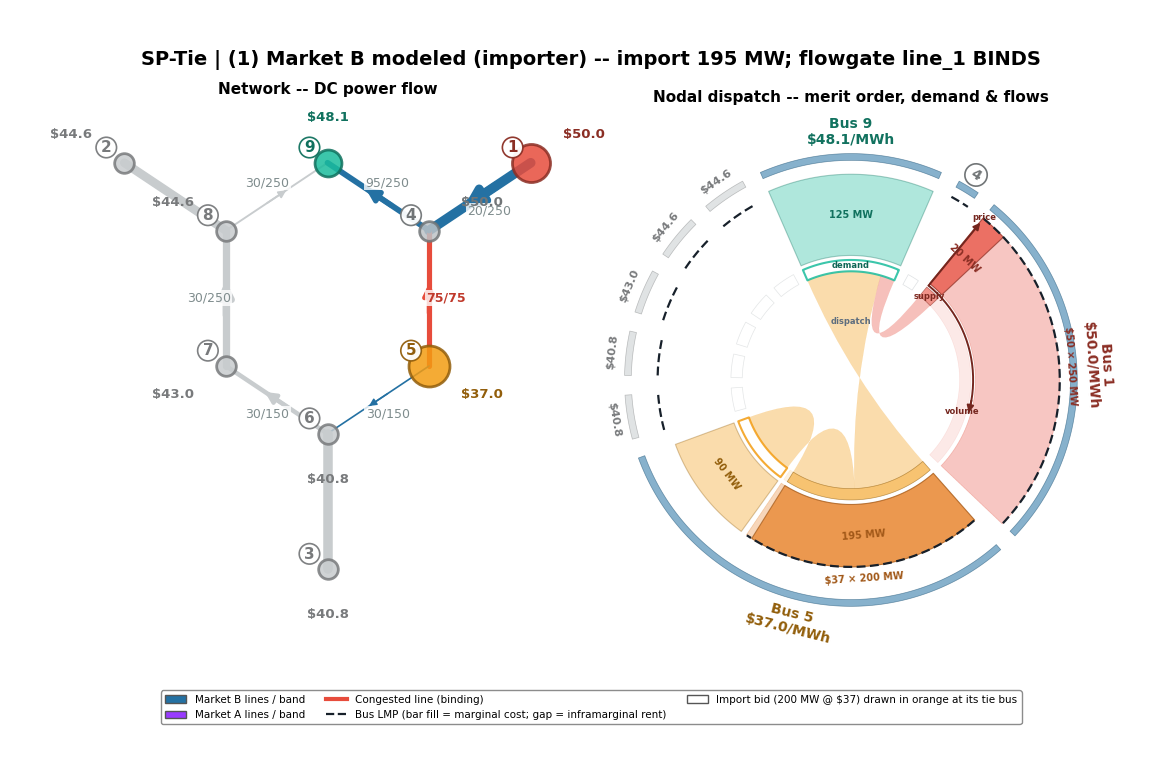

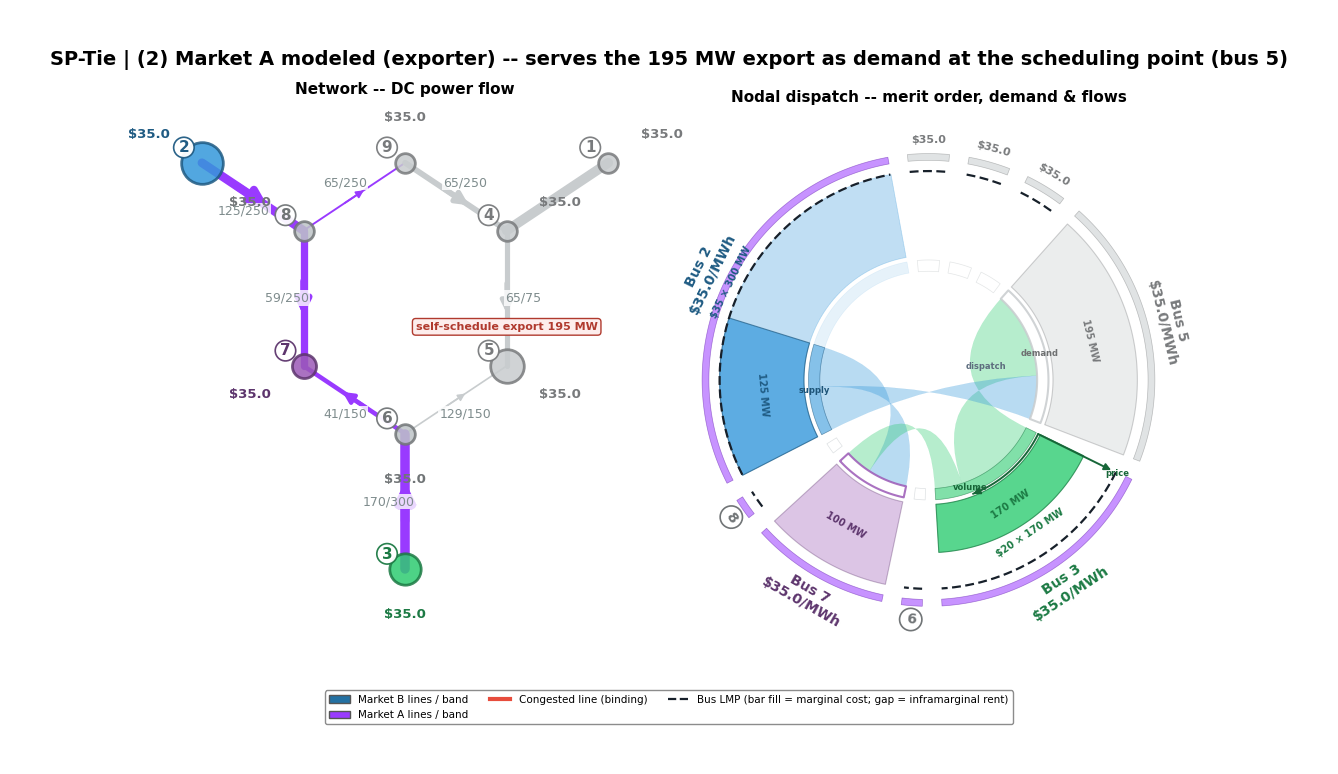

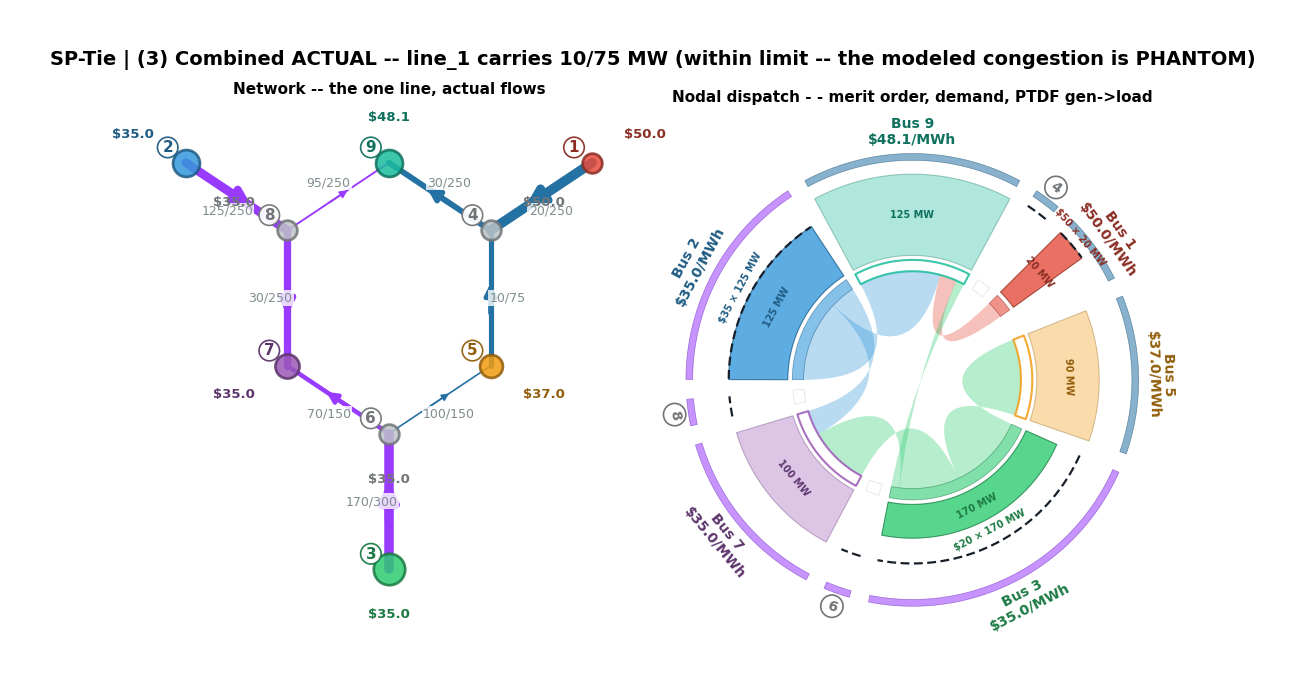

SP-Tie summary:

  (1) Market B models the import at the tie -> flowgate line_1 shows $15/MWh and curtails the

      import to 195 MW; Market B prices separate (bus 5 $37, bus 9 $48).

  (2) Market A dispatches buses 2,3 to serve that export, modeled as demand at the shared

      scheduling point so the energy flows OUT across the intertie toward Market B.

  (3) ACTUAL flow on line_1 is 10/75 MW -- well within limit. The

      SP-Tie congestion was PHANTOM: it came from pinning the import at the tie, not from real power flow.

In [6]:
rCS, rNS, lflowS = three_set("SP")
muCS = rCS.line_dual.get(FLOWGATE, 0.0)
print(f"SP-Tie summary:")
print(f"  (1) Market B models the import at the tie -> flowgate {FLOWGATE} shows ${muCS:.0f}/MWh and curtails the")
print(f"      import to {import_mw(rCS):.0f} MW; Market B prices separate (bus 5 ${rCS.lmp['5']:.0f}, bus 9 ${rCS.lmp['9']:.0f}).")
print(f"  (2) Market A dispatches buses 2,3 to serve that export, modeled as demand at the shared")
print(f"      scheduling point so the energy flows OUT across the intertie toward Market B.")
print(f"  (3) ACTUAL flow on {FLOWGATE} is {abs(lflowS[FLOWGATE]):.0f}/{FLOWGATE_MW:.0f} MW -- well within limit. The")
print(f"      SP-Tie congestion was PHANTOM: it came from pinning the import at the tie, not from real power flow.")


## 3. GAP-Tie — the same three views

The import is now sourced from Market A's DGAP, buses 2 and 3. The rule is the same for
each footprint: the schedule is modeled at the counterparty's GAP. Market B, the
importer, sources at Market A's GAP, buses 2 and 3. Market A, the exporter, delivers at
Market B's GAP, bus 1, because Market A's generation flows out across the intertie
rather than sitting back on its own buses. View (3) is the combined actual, and it
reports whether GAP-Tie's modeled flowgate state matches the line.


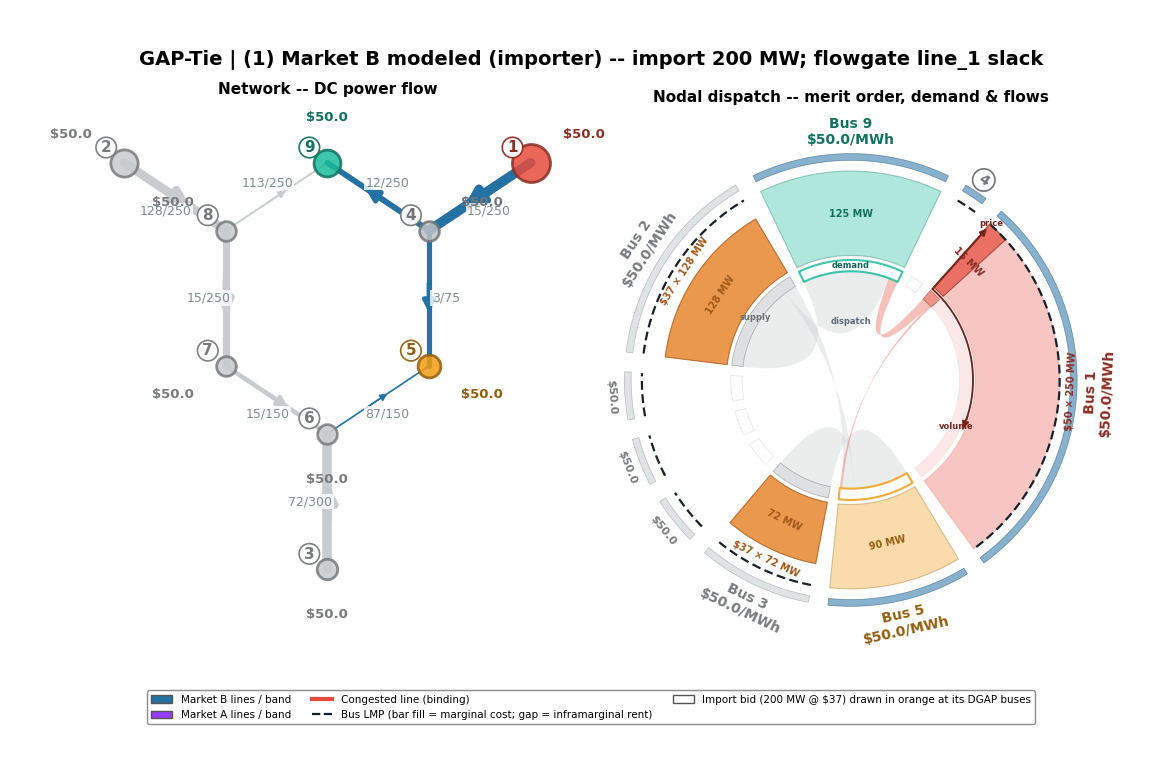

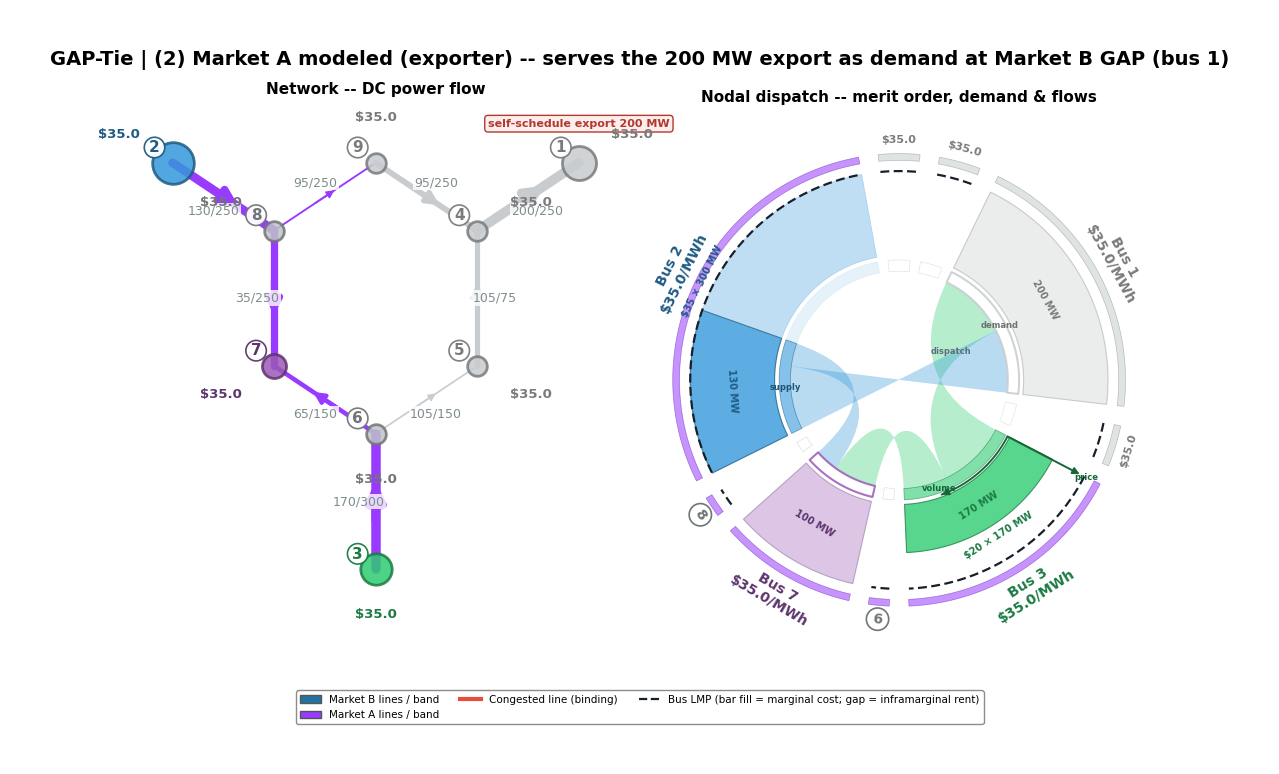

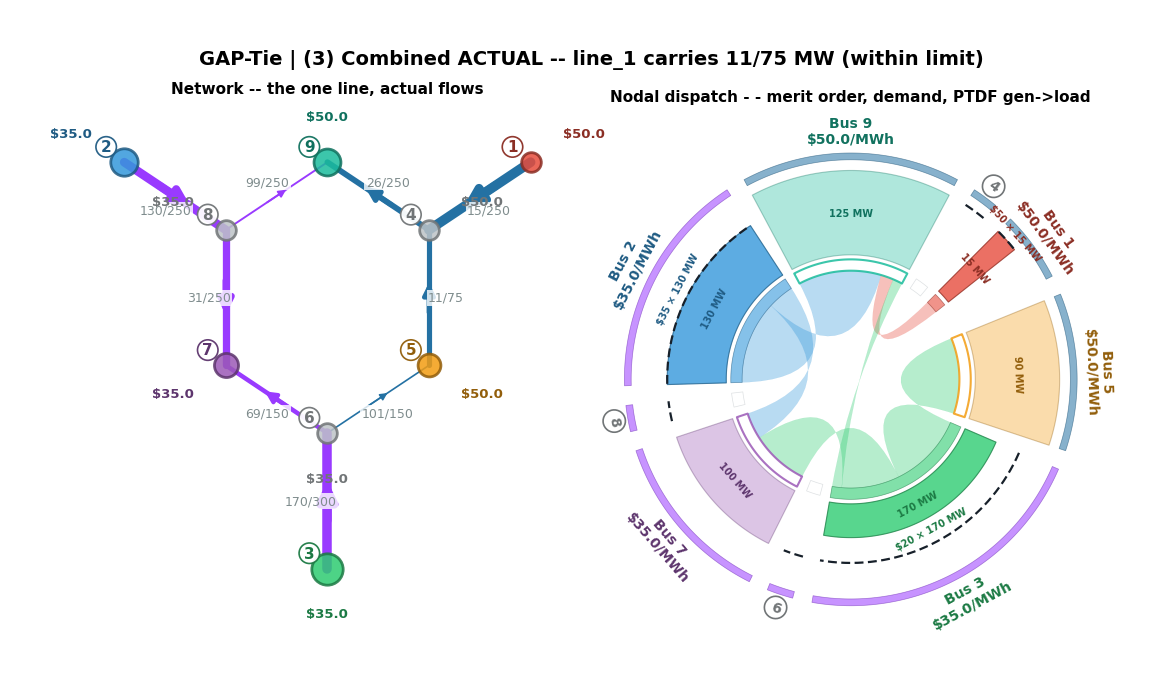

GAP-Tie summary:

  (1) Market B sources the import from the DGAP -> flowgate line_1 stays slack ($0/MWh), the full

      200 MW clears, Market B prices stay uniform ($50).

  (2) Market A dispatches buses 2,3 to serve the export, modeled as demand at Market B GAP (bus 1)

      -- the COUNTERPARTY GAP -- so the energy flows OUT to Market B, not back onto its own gen buses.

  (3) ACTUAL flow on line_1 is 11/75 MW. GAP-Tie's model MATCHES

      reality -- no phantom congestion, and the efficient import is not curtailed.

In [7]:
rCG, rNG, lflowG = three_set("GAP")
muCG = rCG.line_dual.get(FLOWGATE, 0.0)
print(f"GAP-Tie summary:")
print(f"  (1) Market B sources the import from the DGAP -> flowgate {FLOWGATE} stays slack (${muCG:.0f}/MWh), the full")
print(f"      {import_mw(rCG):.0f} MW clears, Market B prices stay uniform (${rCG.lmp['5']:.0f}).")
print(f"  (2) Market A dispatches buses 2,3 to serve the export, modeled as demand at Market B GAP (bus 1)")
print(f"      -- the COUNTERPARTY GAP -- so the energy flows OUT to Market B, not back onto its own gen buses.")
print(f"  (3) ACTUAL flow on {FLOWGATE} is {abs(lflowG[FLOWGATE]):.0f}/{FLOWGATE_MW:.0f} MW. GAP-Tie's model MATCHES")
print(f"      reality -- no phantom congestion, and the efficient import is not curtailed.")


## 4. Comparison — phantom congestion, flow, price, cost

The table compares the two placements of the same import schedule.

In [8]:
def _row(r):
    return {"import shift factor to flowgate": None,
            "import cleared (MW)": round(import_mw(r), 1),
            f"flowgate {FLOWGATE} flow (MW)": round(r.flow_own[FLOWGATE], 1),
            "flowgate shadow price ($/MWh)": round(r.line_dual.get(FLOWGATE, 0.0), 2),
            "Market B LMP bus 5 ($/MWh)": round(r.lmp["5"], 1),
            "Market B LMP bus 9 ($/MWh)": round(r.lmp["9"], 1),
            "production cost ($/h)": round(r.total_cost, 0)}
# the import-only comparison still uses the Market B-modeled clears from the 3-sets
rS, rG = rCS, rCG
colS, colG = _row(rS), _row(rG)
colS["import shift factor to flowgate"] = round(SF_TIE, 3)
colG["import shift factor to flowgate"] = round(SF_DGAP, 3)
cmp = pd.DataFrame({"SP-Tie (at intertie)": colS, "GAP-Tie (at DGAP 2,3)": colG})
display(cmp)
_dc = rS.total_cost - rG.total_cost
print(f"SP-Tie places the import at the tie bus, where its shift factor to {FLOWGATE} is {SF_TIE:+.2f}; the")
print(f"flowgate appears to load and binds, curtailing the cheap import and separating Market B prices.")
print(f"GAP-Tie sources it from Market A's DGAP (shift factor {SF_DGAP:+.2f}); the import follows its real")
print(f"path, the flowgate stays slack, and the full import clears -- ${_dc:,.0f}/h cheaper. The SP-Tie")
print(f"congestion is *phantom*: it reflects the modeling location, not the physical power flow.")
print(f"(The $37 import bid is slightly above Market A's $35 marginal -- a rational offer that clears vs Market B's $50; SP vs GAP moved")
print(f" only WHERE those megawatts sit on the grid.)")
print()
print(f"Modeled vs ACTUAL on {FLOWGATE}:  SP-Tie modeled {abs(rCS.flow_own[FLOWGATE]):.0f}/{FLOWGATE_MW:.0f} (binds) "
      f"but actual {abs(lflowS[FLOWGATE]):.0f}/{FLOWGATE_MW:.0f} -> phantom;  GAP-Tie modeled "
      f"{abs(rCG.flow_own[FLOWGATE]):.0f}/{FLOWGATE_MW:.0f} = actual {abs(lflowG[FLOWGATE]):.0f}/{FLOWGATE_MW:.0f} -> faithful.")


,SP-Tie (at intertie),"GAP-Tie (at DGAP 2,3)"
import shift factor to flowgate,-0.865,-0.453
import cleared (MW),194.800,200.000
flowgate line_1 flow (MW),-75.000,2.900
flowgate shadow price ($/MWh),15.030,0.000
Market B LMP bus 5 ($/MWh),37.000,50.000
Market B LMP bus 9 ($/MWh),48.100,50.000
production cost ($/h),8218.000,8150.000


SP-Tie places the import at the tie bus, where its shift factor to line_1 is -0.86; the

flowgate appears to load and binds, curtailing the cheap import and separating Market B prices.

GAP-Tie sources it from Market A's DGAP (shift factor -0.45); the import follows its real

path, the flowgate stays slack, and the full import clears -- $68/h cheaper. The SP-Tie

congestion is *phantom*: it reflects the modeling location, not the physical power flow.

(The $37 import bid is slightly above Market A's $35 marginal -- a rational offer that clears vs Market B's $50; SP vs GAP moved

 only WHERE those megawatts sit on the grid.)

Modeled vs ACTUAL on line_1:  SP-Tie modeled 75/75 (binds) but actual 10/75 -> phantom;  GAP-Tie modeled 3/75 = actual 11/75 -> faithful.

## 5. The other direction — Market A exports, as a demand bid

The import above was a supply offer. An **export** is its mirror, a **demand bid**
stating a willingness to pay. The low-cost market now sells out. Market A exports up to
100-200 MW to Market B, and Market B is willing to pay \$37/MWh for it, just above
Market A's \$35 marginal cost, the same thin-margin transfer seen from the seller's
side.

The methodology again determines where the export sits as demand and the price it
settles at. **SP-Tie** places the demand at the tie bus, settling at that bus's LMP.
**GAP-Tie** places the demand at the GAP of the market it is delivered to, Market B's
GAP at bus 1, settling at that GAP's LMP. The flowgate is now `line_5` (7-8), internal
to Market A, the seller's "Path 26". As with the import, the full 3-set follows:
**(1)** Market A the exporter, **(2)** Market B the importer, receiving the schedule as
supply and backing down its bus-1 unit, and **(3)** the combined actual line.


In [9]:
EXPORT_MW, EXPORT_BID = 200.0, 37.0           # -- EDIT -- Market A's export to Market B
A_FLOWGATE, A_FLOWGATE_MW = 'line_5', 55.0     # Market A's internal flowgate (7-8): its "Path 26"

def export_bids(mode, E=None, bid=None):
    """Market A's export to Market B as a price-sensitive DEMAND bid (Market B's willingness to
    pay, $37 -- just above Market A's $35 marginal), placed at the tie (SP) or Market B's GAP
    bus 1 (GAP), the counterparty location."""
    E = EXPORT_MW if E is None else E; bid = EXPORT_BID if bid is None else bid
    if mode == "SP":
        return [{"id": "export", "bus": TIE_BUS, "mw": E, "price": bid}]
    return [{"id": f"export_{b}", "bus": b, "mw": E * w, "price": bid} for b, w in B_GAP.items()]

def export_clear(mode):
    net = build_network({A_FLOWGATE: A_FLOWGATE_MW}); pt = compute_ptdf(net, slack_bus="1")
    e = make_engine("Market A", A_BUSES, activated=A_LINES)
    r = solve_engine_dispatch(pt, e, demand_bids=export_bids(mode), shed_price=SHED_PRICE)
    return net, pt, e, r

def export_mw(r):
    return sum(r.demand_cleared.values())

def export_settle_price(mode, r):
    """The price the export settles at, per methodology: the tie LMP (SP) or Market B's GAP-weighted LMP (GAP)."""
    return r.lmp[TIE_BUS] if mode == "SP" else sum(w * r.lmp[b] for b, w in B_GAP.items())

# Reject test: a demand bid below Market A's supply cost does not clear.
_rn = build_network({A_FLOWGATE: A_FLOWGATE_MW})
_rej = solve_engine_dispatch(compute_ptdf(_rn, slack_bus="1"), make_engine("Market A", A_BUSES, activated=A_LINES),
                             demand_bids=[{"id": "lowball", "bus": TIE_BUS, "mw": EXPORT_MW, "price": 18.0}], shed_price=SHED_PRICE)
print(f"Sanity: an export bid at $18 (below Market A's $20-$35 fleet) clears {sum(_rej.demand_cleared.values()):.0f} MW.")

_, _, _, rXS = export_clear("SP")
_, _, _, rXG = export_clear("GAP")
xcmp = pd.DataFrame({
    "SP-Tie (demand at tie bus)": {
        "export bid ($/MWh)": EXPORT_BID,
        "export cleared (MW)": round(export_mw(rXS), 1),
        f"flowgate {A_FLOWGATE} shadow price ($/MWh)": round(rXS.line_dual.get(A_FLOWGATE, 0.0), 2),
        "settles at (per methodology) ($/MWh)": round(export_settle_price("SP", rXS), 1)},
    "GAP-Tie (demand at Market B GAP)": {
        "export bid ($/MWh)": EXPORT_BID,
        "export cleared (MW)": round(export_mw(rXG), 1),
        f"flowgate {A_FLOWGATE} shadow price ($/MWh)": round(rXG.line_dual.get(A_FLOWGATE, 0.0), 2),
        "settles at (per methodology) ($/MWh)": round(export_settle_price("GAP", rXG), 1)},
})
display(xcmp)
print(f"Market A exports to Market B at a ${EXPORT_BID:.0f} demand bid, just above its $35 marginal. SP-Tie puts the")
print(f"withdrawal at the tie -- it phantom-loads {A_FLOWGATE}, binds it, only {export_mw(rXS):.0f} MW of the efficient export")
print(f"clears, settling at ${export_settle_price('SP', rXS):.0f}. GAP-Tie puts it at Market B's GAP -- {A_FLOWGATE} stays slack,")
print(f"the full {export_mw(rXG):.0f} MW clears at ${export_settle_price('GAP', rXG):.0f}. The phantom curtails efficient trade in both directions.")


Sanity: an export bid at $18 (below Market A's $20-$35 fleet) clears 0 MW.

,SP-Tie (demand at tie bus),GAP-Tie (demand at Market B GAP)
export bid ($/MWh),37.00,37.0
export cleared (MW),186.20,200.0
flowgate line_5 shadow price ($/MWh),4.03,0.0
settles at (per methodology) ($/MWh),37.00,35.0


Market A exports to Market B at a $37 demand bid, just above its $35 marginal. SP-Tie puts the

withdrawal at the tie -- it phantom-loads line_5, binds it, only 186 MW of the efficient export

clears, settling at $37. GAP-Tie puts it at Market B's GAP -- line_5 stays slack,

the full 200 MW clears at $35. The phantom curtails efficient trade in both directions.

=== SP-Tie export: the three views ===

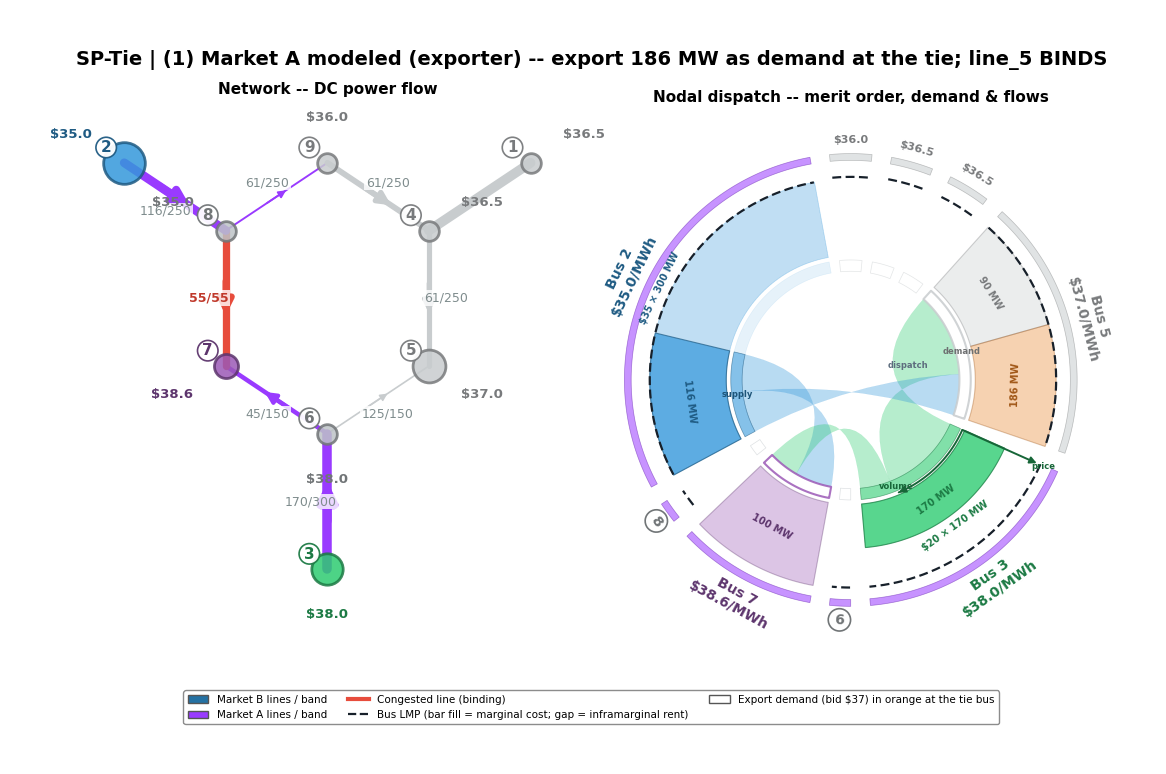

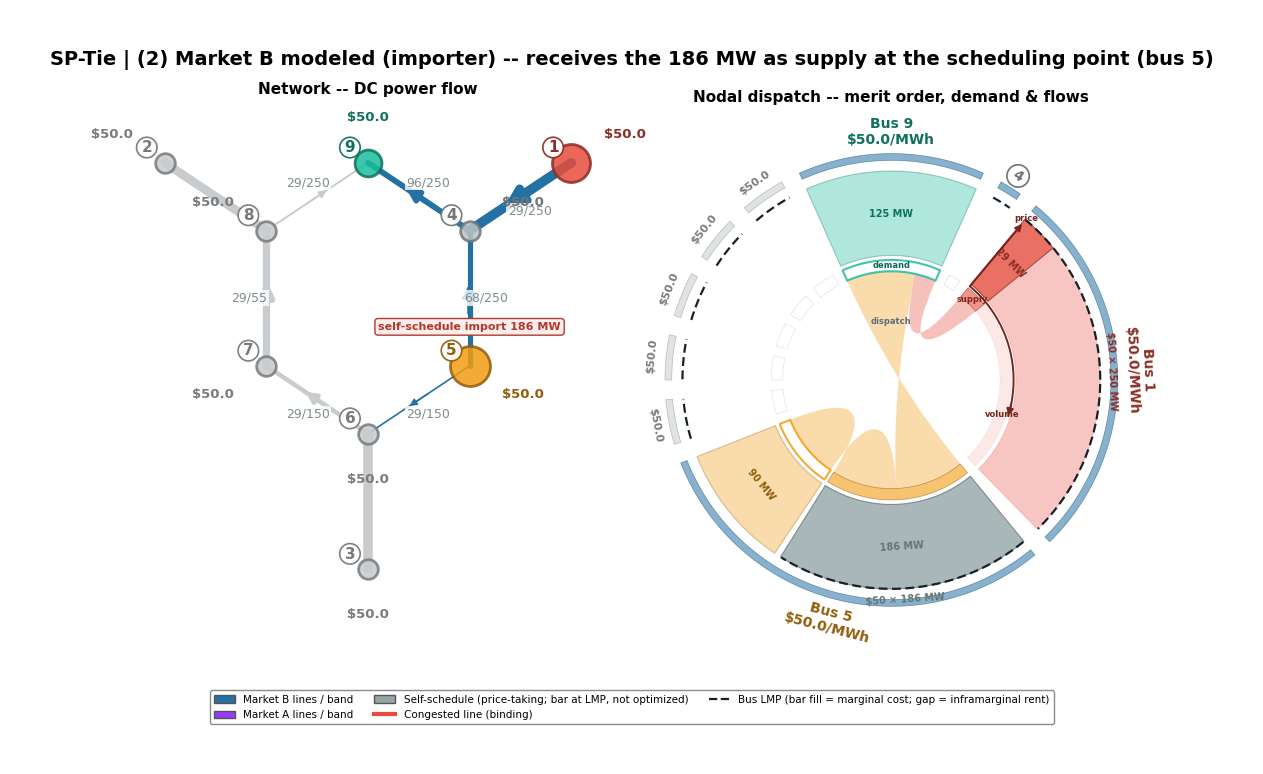

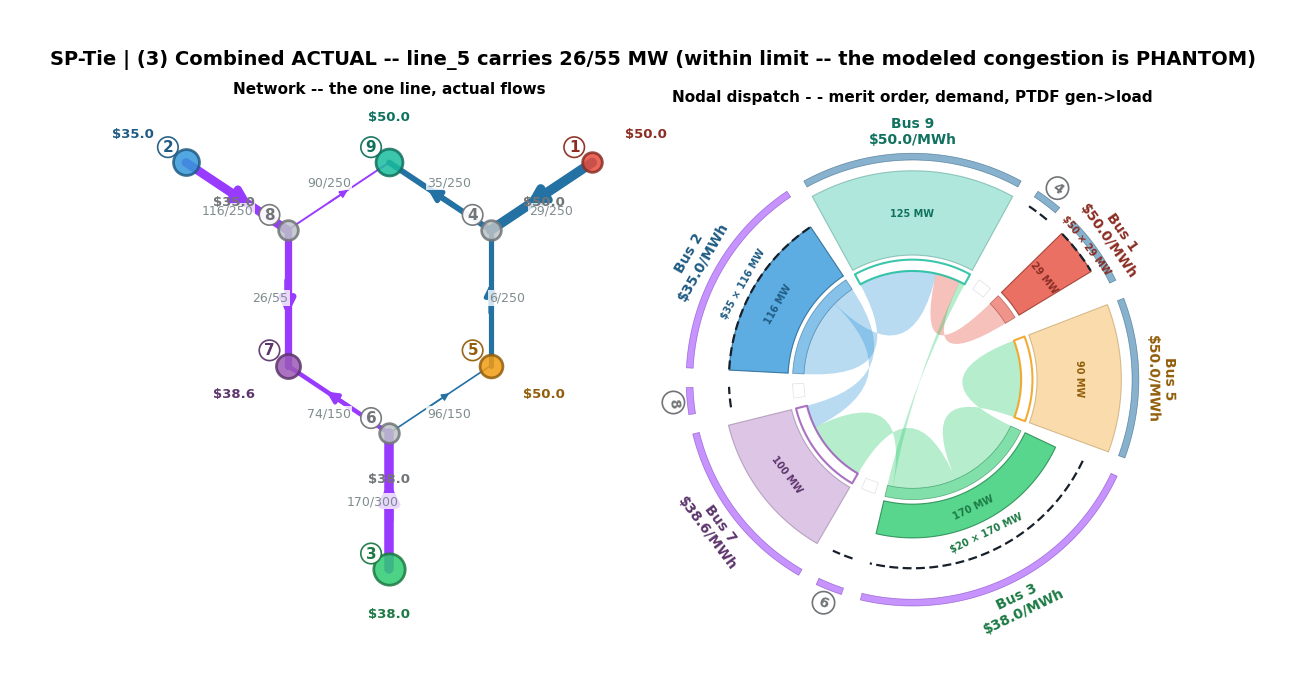

In [10]:
print("=== SP-Tie export: the three views ===")
rCXS, rNXS, lflowXS = export_three_set("SP")

=== GAP-Tie export: the three views ===

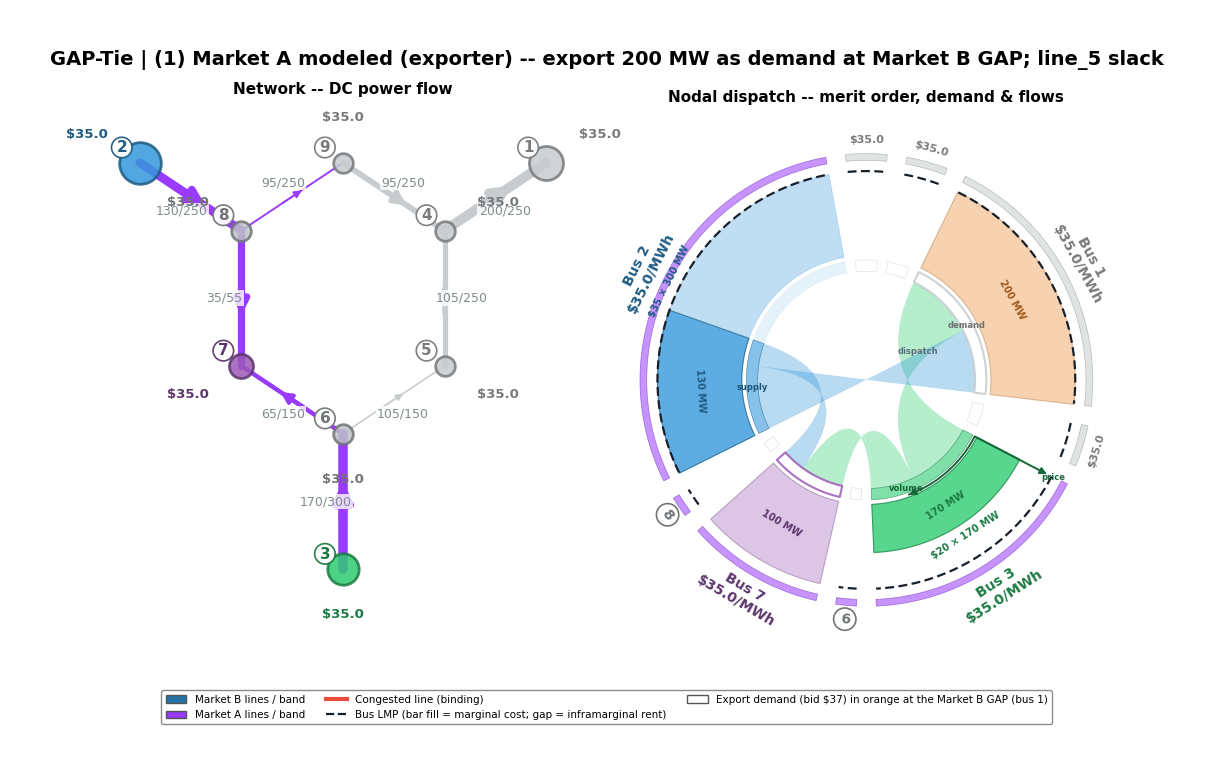

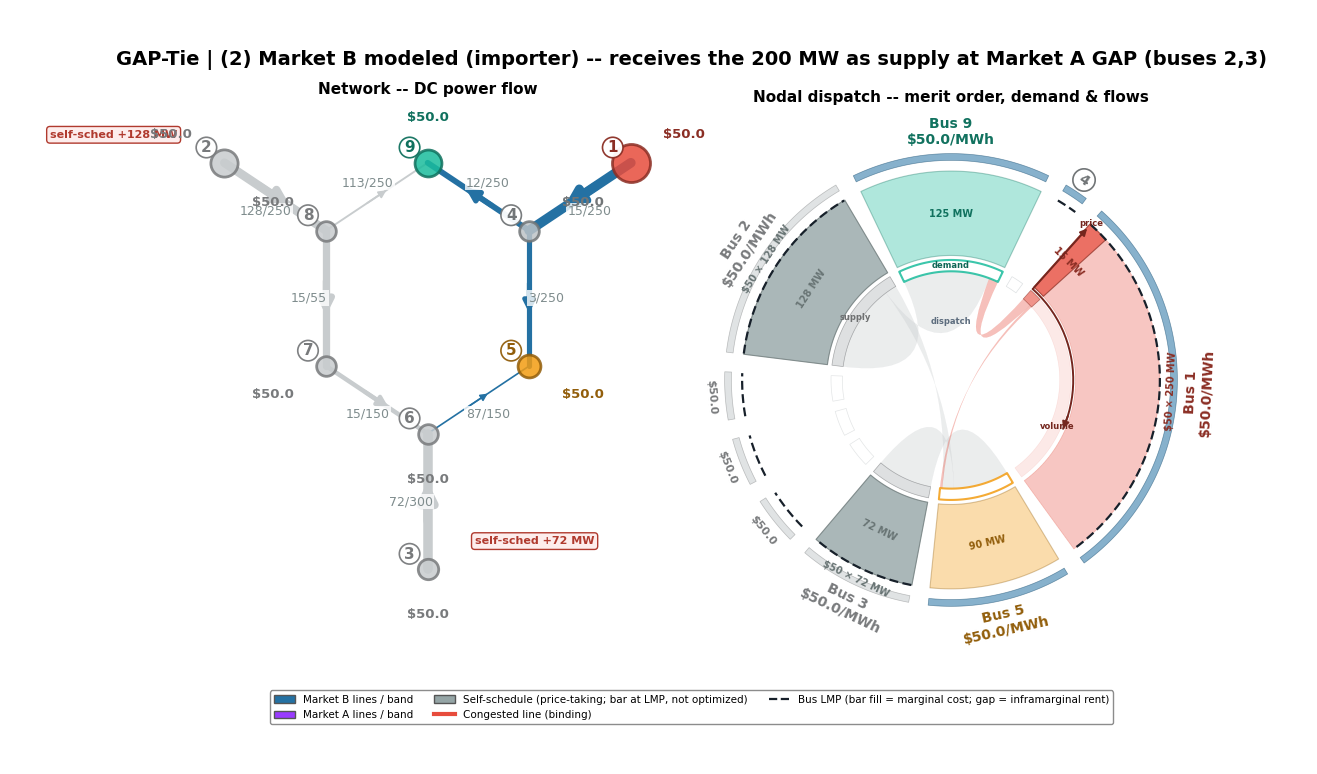

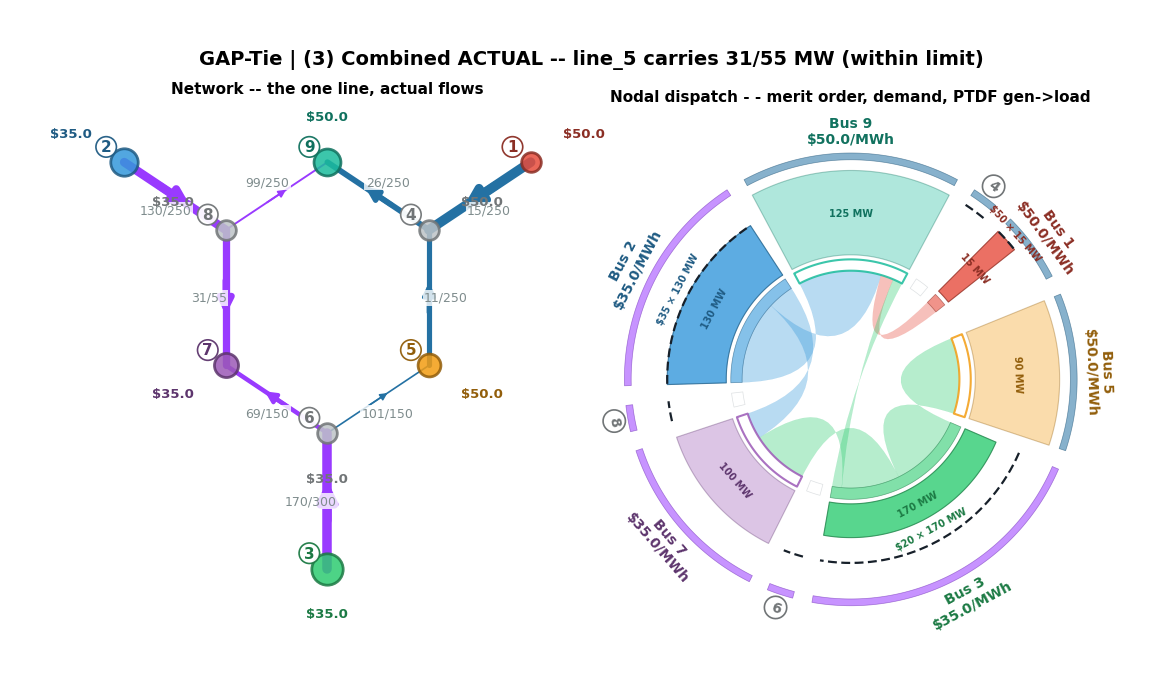

In [11]:
print("=== GAP-Tie export: the three views ===")
rCXG, rNXG, lflowXG = export_three_set("GAP")

## 6. Cost uncertainty — a price-sensitive transfer

The clears above fixed the costs. This section makes the two markets' marginal costs
random draws, taken with the shared `risk.py` primitives. The import is now
**price-sensitive**. Market A offers slightly above its realized marginal cost, and the
schedule clears only while that offer is below Market B's realized unit cost. The
cleared transfer, and the SP-Tie phantom congestion it triggers, are therefore
themselves random.

Integrating over the cost draws by Gauss-Hermite quadrature, SP-Tie's phantom congestion
is systematic. In every cost state where the import is worth clearing, SP-Tie curtails
more of it than GAP-Tie does. The **expected phantom cost** is the price of the modeling
error carried across all states.

Cost uncertainty -- Market A ~ N(35, 5), Market B ~ N(50, 12):

  the transfer is economic (the bid beats Market B's realized cost) in 85% of states.

  Across those, E[phantom cost of SP-Tie] = $87/h (GAP-Tie carries none); worst $530/h.

  SP-Tie curtails the efficient import in EVERY economic state -- a systematic tax: the modeling

  location, not the realized costs, is what forgoes the trade. GAP-Tie's accuracy removes it.

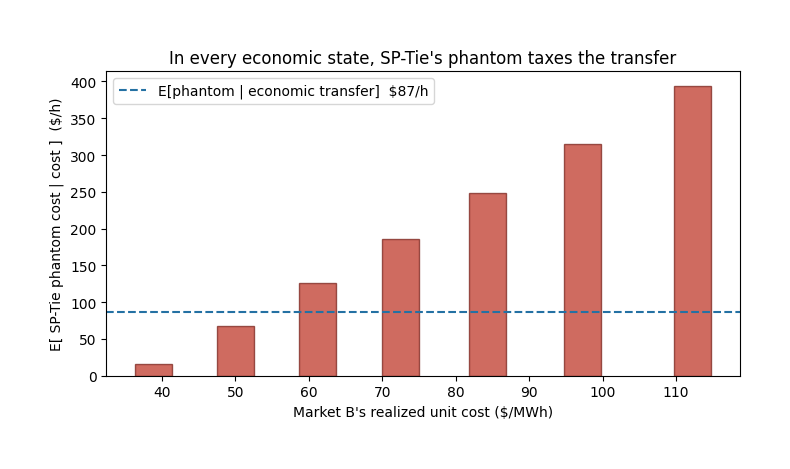

In [12]:
import numpy as np
# -- EDIT -- cost uncertainty (the seams-notebook model: marginal costs are uncertain tomorrow)
A_COST_SD = 5.0      # sd of Market A's marginal cost ($/MWh); mean $35 (the low-cost source)
B_COST_SD = 12.0     # sd of Market B's unit cost ($/MWh); mean $50 (the importer's alternative)
N_NODES   = 11       # Gauss-Hermite quadrature nodes per cost
MARGIN    = 2.0      # Market A bids its realized marginal cost + this margin
# -----------------------------------------------------------------------------
zA, wA = np.polynomial.hermite_e.hermegauss(N_NODES); wA = wA / wA.sum()
zB, wB = np.polynomial.hermite_e.hermegauss(N_NODES); wB = wB / wB.sum()
cA_nodes = 35.0 + A_COST_SD * zA      # Market A marginal-cost grid (its bell)
cB_nodes = 50.0 + B_COST_SD * zB      # Market B unit-cost grid

def clear_uncertain(mode, cA, cB):
    """Clear Market B with the import bid = Market A's realized cost + margin, against Market B's
    realized unit cost cB -- the price-sensitive transfer at one cost state."""
    net = build_net(); pt = compute_ptdf(net, slack_bus="1")
    e = make_engine("Market B", B_BUSES, activated=B_LINES); e.gens = dict(e.gens)
    e.gens["gen_slack_0"] = {**e.gens["gen_slack_0"], "cost": float(cB)}
    e.gens.update({k: {**v, "cost": float(cA + MARGIN)} for k, v in tie_inject(mode).items()})
    r = solve_engine_dispatch(pt, e, shed_price=SHED_PRICE)
    return import_mw(r), r.total_cost

impS = np.zeros((N_NODES, N_NODES)); impG = np.zeros_like(impS); phantom = np.zeros_like(impS)
for i, cA in enumerate(cA_nodes):
    for j, cB in enumerate(cB_nodes):
        iS, kS = clear_uncertain("SP", cA, cB)
        iG, kG = clear_uncertain("GAP", cA, cB)
        impS[i, j], impG[i, j], phantom[i, j] = iS, iG, kS - kG
W = wA[:, None] * wB[None, :]                    # joint quadrature weights (independent draws)
# Economic states: the transfer is worth clearing (Market B's realized cost beats the bid), so GAP
# clears the full import and SP-Tie's curtailment is a genuine phantom (not flowgate reliability).
econ = (cB_nodes[None, :] > (cA_nodes[:, None] + MARGIN))
ph_econ = np.where(econ, phantom, 0.0)
Wn = float(np.sum(W * econ))

print(f"Cost uncertainty -- Market A ~ N(35, {A_COST_SD:.0f}), Market B ~ N(50, {B_COST_SD:.0f}):")
print(f"  the transfer is economic (the bid beats Market B's realized cost) in {Wn*100:.0f}% of states.")
print(f"  Across those, E[phantom cost of SP-Tie] = ${np.sum(W*ph_econ)/Wn:.0f}/h (GAP-Tie carries none); worst ${phantom.max():.0f}/h.")
print(f"  SP-Tie curtails the efficient import in EVERY economic state -- a systematic tax: the modeling")
print(f"  location, not the realized costs, is what forgoes the trade. GAP-Tie's accuracy removes it.")

# Figure: the phantom cost across Market B's realized cost, over the economic region -- it grows with
# the gain from trade SP-Tie needlessly forgoes.
mask = cB_nodes > 38.0
fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.bar(cB_nodes[mask], (wA @ ph_econ)[mask], width=B_COST_SD * 0.42, color="#C0392B", alpha=0.75, ec="#7B241C")
ax.axhline(np.sum(W * ph_econ) / Wn, color="#2471A3", ls="--", lw=1.5,
           label=f"E[phantom | economic transfer]  ${np.sum(W*ph_econ)/Wn:.0f}/h")
ax.set_xlabel("Market B's realized unit cost ($/MWh)")
ax.set_ylabel("E[ SP-Tie phantom cost | cost ]  ($/h)")
ax.set_title("In every economic state, SP-Tie's phantom taxes the transfer")
ax.legend(); plt.tight_layout(); plt.show()


## 7. Sandbox

The flowgate rating and the import size are the sandbox inputs. Tightening the flowgate
grows SP-Tie's phantom congestion while GAP-Tie is unaffected. Relaxing the flowgate
converges the two designs.

================= SP-Tie import, 3-set =================

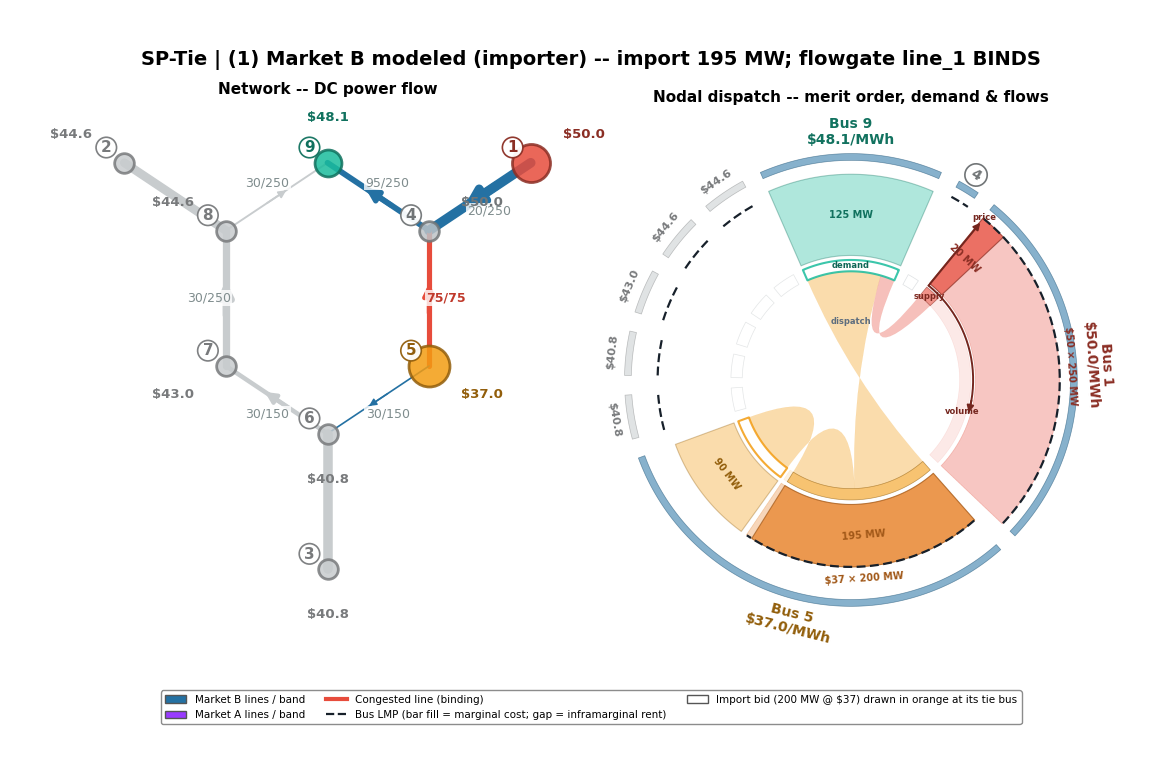

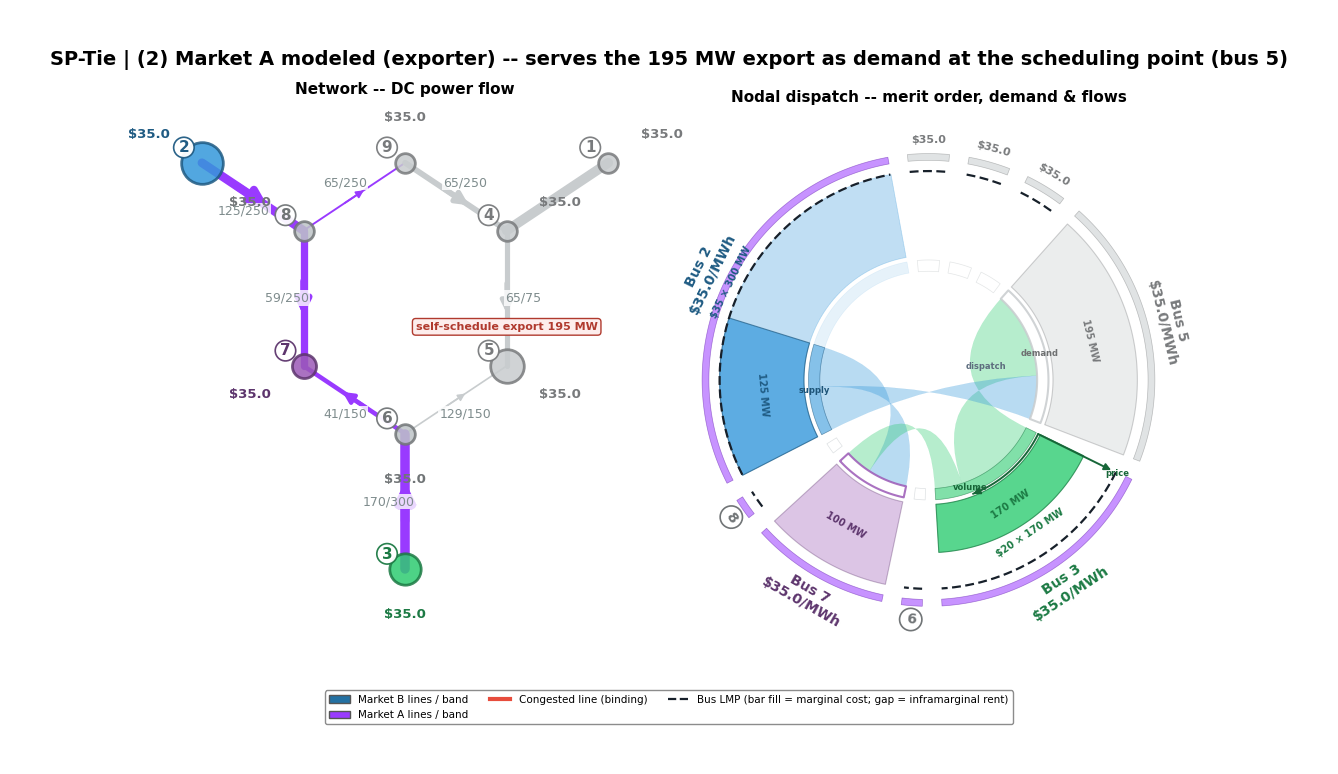

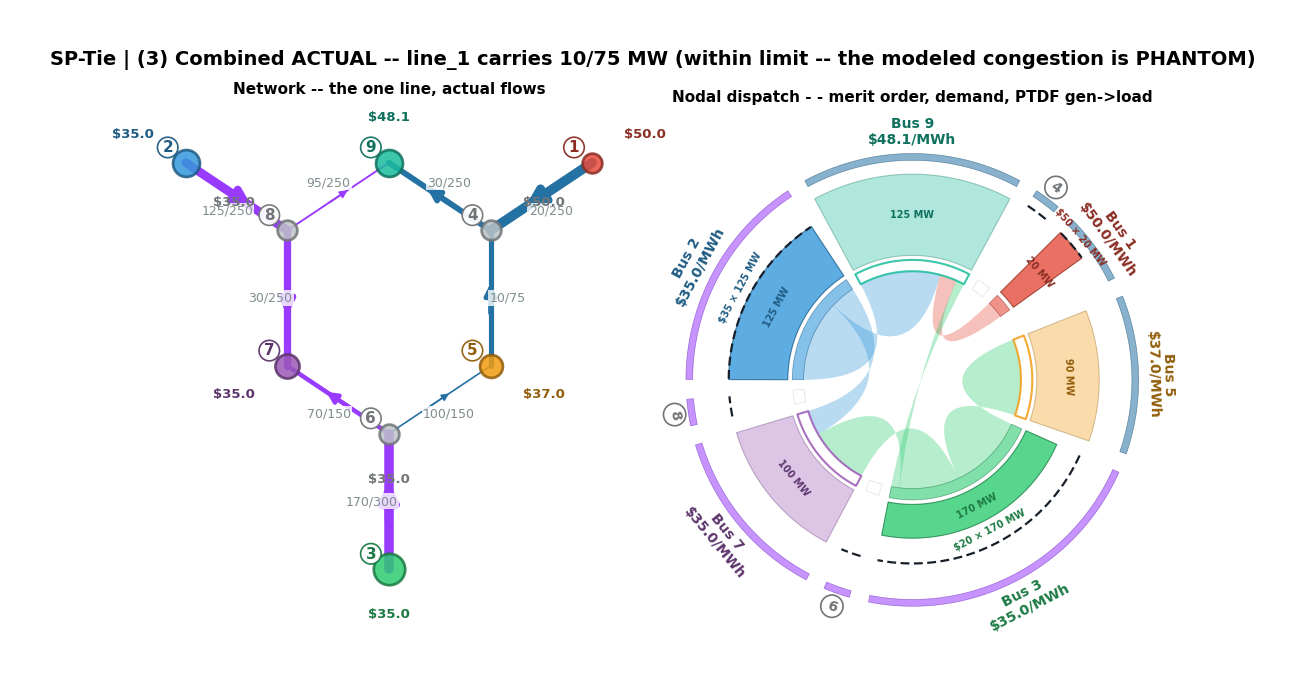

================= GAP-Tie import, 3-set =================

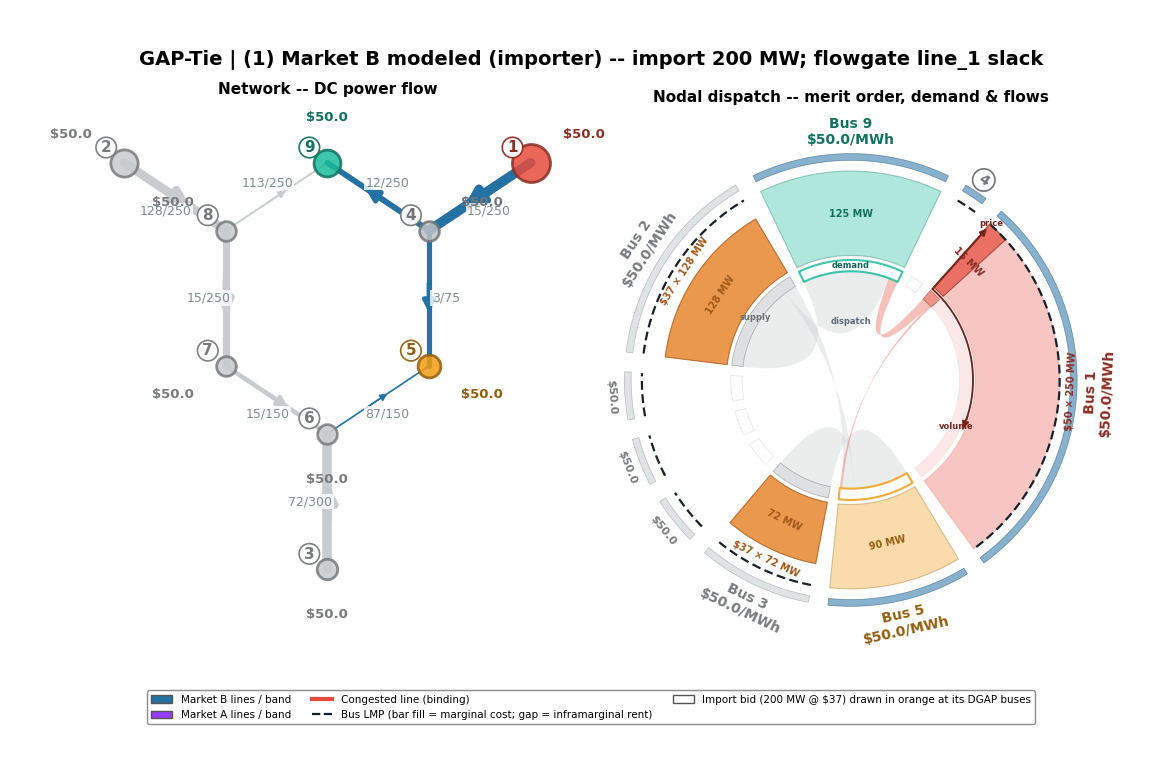

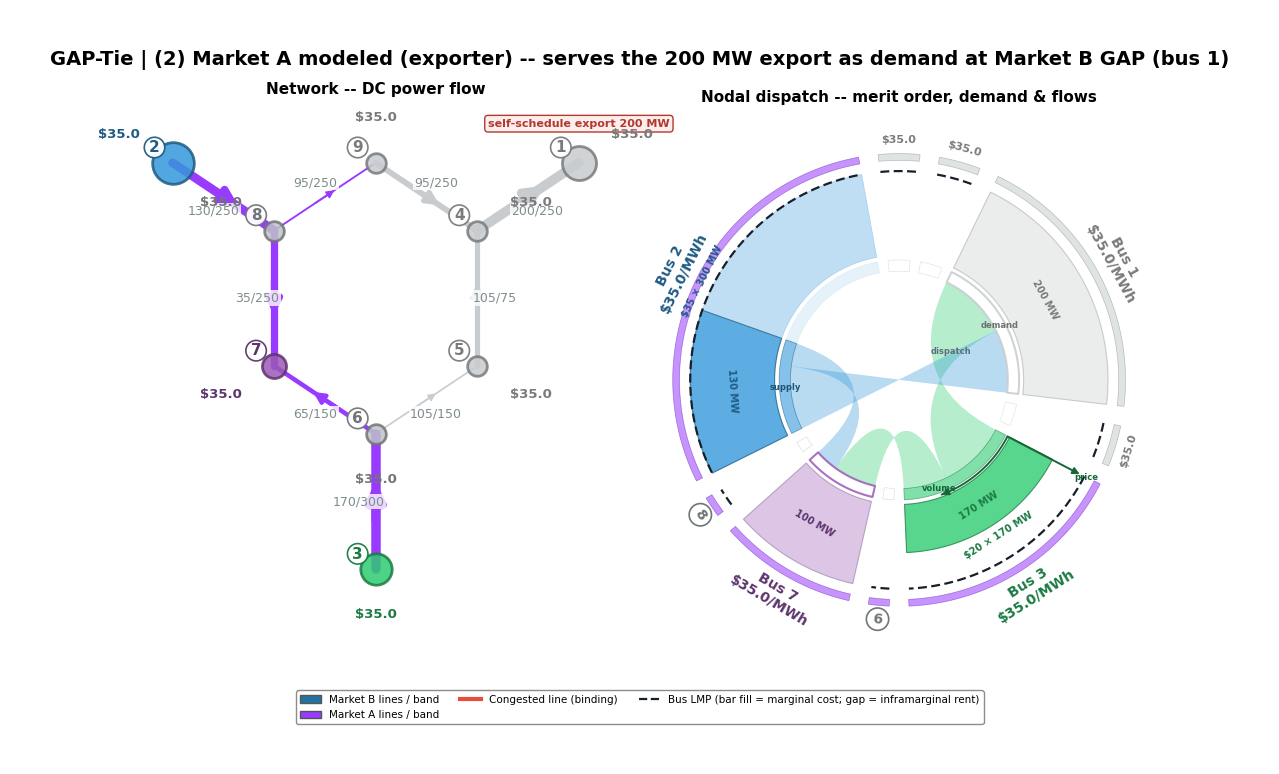

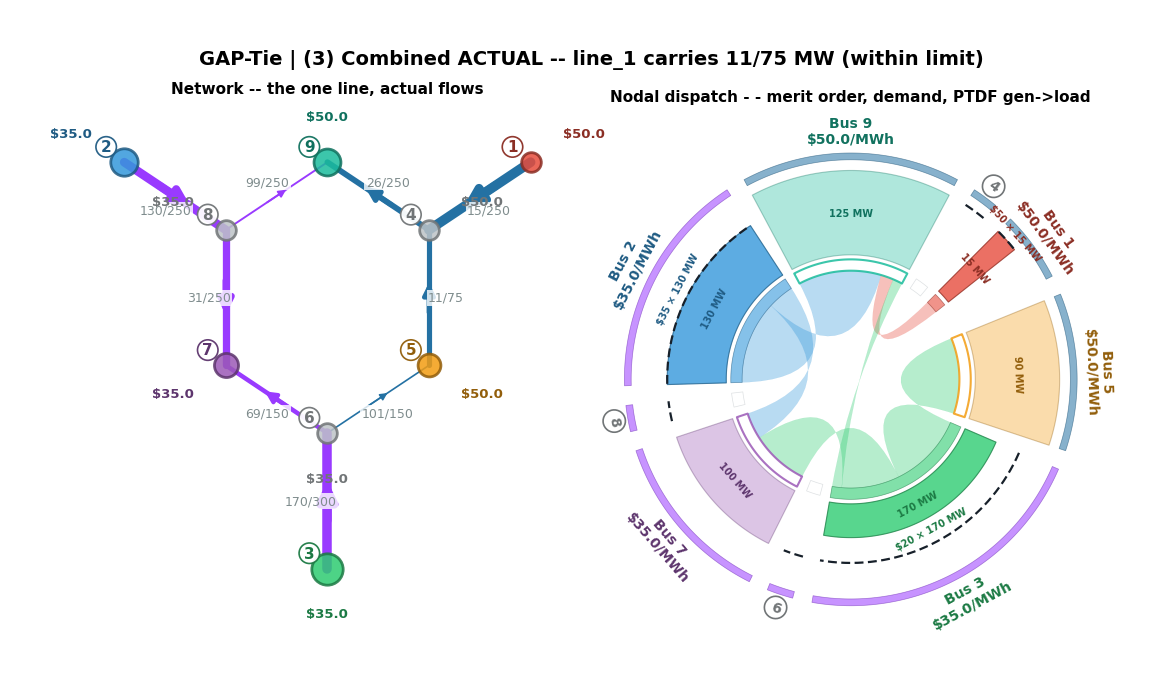

In [13]:
# ============================ SANDBOX -- EDIT HERE ============================
SB_DIRECTION   = "import"   # "import" (supply bid) or "export" (demand bid)
SB_FLOWGATE_MW = 75.0       # flowgate rating (MW); lower -> more SP-Tie phantom congestion
SB_QUANTITY    = 200.0      # bid quantity (MW)
SB_BID         = 37.0       # bid price $/MWh (import supply offer ~slightly above Market A's $35; export willingness-to-pay)
# =============================================================================
# Re-run the full 3-set -- (1) Market B modeled, (2) the other footprint modeled, (3) combined
# ACTUAL -- for both SP-Tie and GAP-Tie at the chosen settings and direction.
if SB_DIRECTION == "import":
    FLOWGATE_MW, IMPORT_MW, IMPORT_BID = SB_FLOWGATE_MW, SB_QUANTITY, SB_BID
    intertie.configure(flowgate_mw=FLOWGATE_MW, schedule_mw=IMPORT_MW, import_bid=IMPORT_BID)
    for _m in ("SP", "GAP"):
        print(f"================= {_m}-Tie import, 3-set =================")
        three_set(_m)
else:
    A_FLOWGATE_MW, EXPORT_MW, EXPORT_BID = SB_FLOWGATE_MW, SB_QUANTITY, SB_BID  # export flowgate = line_5 (try ~55)
    for _m in ("SP", "GAP"):
        print(f"================= {_m}-Tie export, 3-set =================")
        export_three_set(_m)
